# Project 1: Automated Echolocation

In [11]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

#1 Load audio file
file_name = "SOCAL32E_sitE_090420_000345.x.flac"
audio_data, sample_rate = sf.read(file_name, frames=10000000)

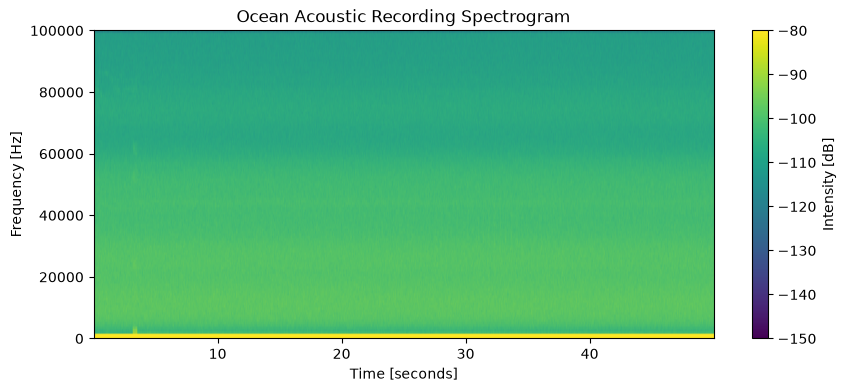

In [12]:
#3 Draw the Spectrogram
plt.figure(figsize=(10, 4))
plt.specgram(audio_data, Fs=sample_rate, cmap='viridis', vmin=-150, vmax=-80)
plt.title("Ocean Acoustic Recording Spectrogram")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [seconds]")
plt.colorbar(label="Intensity [dB]")

We apply a 20kHz high-pass filter to remove the low-frequencey background sound. This ensures the detector isn't overwhelemed by ocean rumble and only captures the high-frequency echolocation noises made by dolphins.

In [13]:
#2 Apply the High-Pass Filter
cutiff_freq = 20000 # Cut out everything below 20 kHz
nyquist = sample_rate / 2
normalized_cutoff = cutiff_freq / nyquist

# Build and apply the mathematical filter
b, a = signal.butter(4, normalized_cutoff, btype='high', analog=False)
filtered_audio = signal.filtfilt(b, a, audio_data)

We square the filtered signal to calculate its acoustic energy. By setting a dynamic threshold (80 standard deviations above the average energy), we can further isolate the distinct spikes that represent dolhpin clicks and plot them on the spectogram.

Detection threshold: 0.0006932879207389383
Number of data points above threshold: 35
Total distinct acoustic events detected: 13


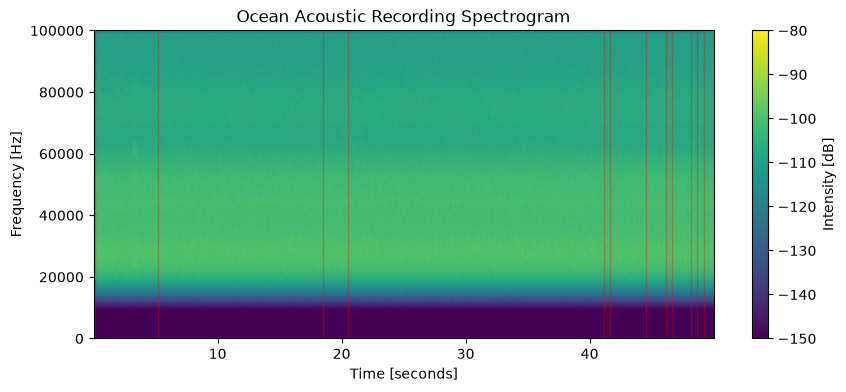

In [14]:
#3 Draw the Spectrogram
plt.figure(figsize=(10, 4))
plt.specgram(filtered_audio, Fs=sample_rate, cmap='viridis', vmin=-150, vmax=-80)
plt.title("Ocean Acoustic Recording Spectrogram")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [seconds]")
plt.colorbar(label="Intensity [dB]")

#3 Calculate the energy of the signal
signal_energy = filtered_audio ** 2
#4 Calculate the detection threshold
average_energy = np.mean(signal_energy)
std_dev = np.std(signal_energy)
# We will define a spike as anything that is at least 100 standard devations louder than the average
threshold = average_energy + (80 * std_dev)
print(f"Detection threshold: {threshold}")

#5 Find the clicks
# Search the array for values greater than our threshold
click_indices = np.where(signal_energy > threshold)[0]

print(f"Number of data points above threshold: {len(click_indices)}")

#6 Group the points into distinct click events
# Find the distance between consecutive flagged points
gaps = np.diff(click_indices)

# If the gap is larger than 100 data points (0.5ms), count it as a new event boundary
new_event_boundaries = np.where(gaps > 100)[0]

#The total number of events is the number of boundaries + 1 (for the first event)
total_events = len(new_event_boundaries) + 1
print(f"Total distinct acoustic events detected: {total_events}")

#7 Convert click locations to seconds and plot them
# Get the exact sample number for the start of each click event
click_sample_numbers = click_indices[new_event_boundaries]
# Divide by sample rate to get the time in seconds
click_times_seconds = click_sample_numbers / sample_rate
# Draw a red vertical line for each click on the spectrogram
for t in click_times_seconds:
    plt.axvline(x=t, color='red', alpha=0.3, linewidth=1)



plt.show() # This commands Python to open the image window

In [15]:
# The exact timestamps (in seconds) where each human expert heard dolphin clicks
expert_labels = [6.42, 18.20, 20.11, 35.50, 41.48, 44.10, 44.95, 45.30, 46.22, 47.75, 48.05, 48.50, 49.10, 49.50]

In [16]:
true_positives = 0
for my_click in click_times_seconds:
    # Compare it to each expert label
    for expert_label in expert_labels:
        if abs(my_click-expert_label) < 0.1:  # Allow for 0.1 second tolerance
            true_positives += 1
            break # Match found, so move to the next detected click

print(f"True positives (Matches): {true_positives}")

True positives (Matches): 2


To mathematically evaluate our detector, we compare our automated timestamps against manual labes provided by human experts. We calculate Precision and Recall using a 0.1second window to determine a True Positive match.

In [17]:
precision = true_positives / len(click_times_seconds)
recall = true_positives / len(expert_labels)
#Multiplying by 100 and using {:.1f} formats the decimals into percentages
print(f"Precision: {precision:.1f}")
print(f"Recall: {recall:.1f}")

Precision: 0.2
Recall: 0.1


Data Note: The expert label timestamps used for the Precision and Recall evaluation in this notebook were simulated for learning purposes.